<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




# جلسه ۶ — کاربردهای SVD در دنیای واقعی + شبه‌وارون مور-پنروز
### مبانی ریاضی یادگیری ماشین | بخش دوم: جبر خطی پیشرفته

**اهداف یادگیری این جلسه:**
- استفاده از SVD **کوتاه‌شده (Truncated SVD)** برای فشرده‌سازی داده/تصویر
- ساخت یک سیستم پیشنهادگر (Recommender System) بسیار ساده با تقریب رتبه‌پایین (Low-Rank Approximation)
- فهم و استفاده از شبه‌وارون مور-پنروز (Moore–Penrose Pseudoinverse) برای حل مسائلی که «وارون معمولی» ندارند

> 📘 **جعبه واژه‌نامه** — هر جا اصطلاح تخصصی جدیدی به‌کار می‌رود، همین‌جا با یک مثال ساده و غیرتخصصی توضیح داده می‌شود. لازم نیست از قبل این کلمات را بلد باشید.

> **پیش‌مطالعه:** یادآوری فرمول $A = U\Sigma V^\top$ از جلسه‌ی قبل.


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## 🎯 چالش واقعی این جلسه: نتفلیکس/فیلیمو/نماوا/... چطور فیلم بعدی را به شما پیشنهاد می‌دهد؟

فرض کنید یک جدول داریم: هزاران کاربر در سطرها، هزاران فیلم در ستون‌ها، و هر خانه امتیاز آن کاربر به آن فیلم (اگر دیده باشد). مشکل این‌جاست: **بیشتر خانه‌های این جدول خالی‌اند** — هیچ کاربری همه‌ی فیلم‌ها را ندیده. چطور می‌توان امتیاز احتمالی یک کاربر به فیلمی که ندیده را حدس زد؟

ایده: شاید سلیقه‌ی هر کاربر و ژانر هر فیلم را بتوان با چند «بُعد پنهان» ساده توصیف کرد (مثلاً «میزان علاقه به اکشن»، «میزان علاقه به عاشقانه»)، و امتیاز واقعی چیزی نیست جز حاصل‌ضرب این بُعدهای پنهان. این دقیقاً همان کاری است که SVD کوتاه‌شده انجام می‌دهد. بیایید ببینیم.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ماتریس امتیاز: ۶ کاربر × ۵ فیلم. صفر یعنی «هنوز ندیده»
ratings = torch.tensor([
    [5.0, 4.0, 0.0, 1.0, 0.0],
    [4.0, 5.0, 0.0, 0.0, 1.0],
    [1.0, 0.0, 5.0, 4.0, 5.0],
    [0.0, 1.0, 4.0, 5.0, 4.0],
    [5.0, 5.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 5.0, 5.0, 4.0],
])

U, S, Vt = torch.linalg.svd(ratings, full_matrices=False)
print(S.round(decimals=2).tolist())
print("مقادیر تکین:", S.round(decimals=2).tolist())
print("→ دو مقدار اول خیلی بزرگ‌ترند: یعنی سلیقه‌ی کاربران را می‌توان تقریباً با ۲ «بُعد پنهان» توصیف کرد")


[14.0, 11.140000343322754, 1.6100000143051147, 1.4800000190734863, 1.0]
مقادیر تکین: [14.0, 11.140000343322754, 1.6100000143051147, 1.4800000190734863, 1.0]
→ دو مقدار اول خیلی بزرگ‌ترند: یعنی سلیقه‌ی کاربران را می‌توان تقریباً با ۲ «بُعد پنهان» توصیف کرد


In [2]:
def low_rank_approx(U, S, Vt, k):
    # فقط k مقدار تکین اول را نگه می‌داریم و بقیه را صفر می‌کنیم
    return U[:, :k] @ torch.diag(S[:k]) @ Vt[:k, :]

approx_rank2 = low_rank_approx(U, S, Vt, k=2)
print("امتیازهای واقعی:\n", ratings)
print("\nامتیازهای بازسازی‌شده با فقط ۲ بُعد پنهان:\n", approx_rank2.round(decimals=2))
print("\n📌 به خانه‌هایی که در داده‌ی اصلی صفر بودند (یعنی کاربر ندیده) نگاه کنید —")
print("   الان یک عدد غیرصفر دارند: این پیش‌بینی سیستم پیشنهادگر ماست!")


امتیازهای واقعی:
 tensor([[5., 4., 0., 1., 0.],
        [4., 5., 0., 0., 1.],
        [1., 0., 5., 4., 5.],
        [0., 1., 4., 5., 4.],
        [5., 5., 1., 0., 0.],
        [0., 0., 5., 5., 4.]])

امتیازهای بازسازی‌شده با فقط ۲ بُعد پنهان:
 tensor([[ 4.5000,  4.5000,  0.3600,  0.3200,  0.3400],
        [ 4.5000,  4.5000,  0.3300,  0.3000,  0.3200],
        [ 0.5200,  0.4900,  4.7800,  4.7600,  4.4300],
        [ 0.5100,  0.4900,  4.4500,  4.4300,  4.1200],
        [ 5.0000,  5.0000,  0.3600,  0.3200,  0.3500],
        [ 0.0100, -0.0100,  4.8000,  4.7800,  4.4500]])

📌 به خانه‌هایی که در داده‌ی اصلی صفر بودند (یعنی کاربر ندیده) نگاه کنید —
   الان یک عدد غیرصفر دارند: این پیش‌بینی سیستم پیشنهادگر ماست!


### 🗣️ بحث دو‌نفره (Think–Pair–Share) — ۲ دقیقه
نگاه کنید کاربر ۱ (سطر اول) هنوز فیلم ۳ و ۵ را ندیده. عدد پیش‌بینی‌شده برای این دو فیلم چقدر است؟ آیا با الگوی امتیازهای واقعی کاربر ۱ (که به فیلم‌های ۱ و ۲ امتیاز بالا داده) هم‌خوانی منطقی دارد؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>






### 📐 چرا Truncated SVD «بهترین» تقریب است؟ قضیه‌ی اکارت–یانگ–میرسکی

تا اینجا $k$ مقدار تکین اول را نگه داشتیم و بقیه را صفر کردیم. این کار یک انتخاب دلبخواهی نیست؛ پشتوانه‌ی دقیق ریاضی دارد.

**نمادگذاری.** فرض کنید $A \in \mathbb{R}^{m \times n}$ دارای SVD زیر باشد:

$$
A = \sum_{i=1}^{r} \sigma_i\, u_i v_i^\top, \qquad \sigma_1 \ge \sigma_2 \ge \cdots \ge \sigma_r > 0, \quad r = \operatorname{rank}(A)
$$

برای $1 \le k \le r$، **SVD کوتاه‌شده‌ی رتبه‌ی $k$** را این‌طور تعریف می‌کنیم:

$$
A_k = \sum_{i=1}^{k} \sigma_i\, u_i v_i^\top = U_k \Sigma_k V_k^\top
$$

(قرارداد: $\sigma_i = 0$ برای $i > r$.)

---

**قضیه (اکارت–یانگ–میرسکی).** برای هر ماتریس $B \in \mathbb{R}^{m \times n}$ با $\operatorname{rank}(B) \le k$:

$$
\|A - A_k\|_2 = \sigma_{k+1} \;\le\; \|A - B\|_2
$$

$$
\|A - A_k\|_F = \sqrt{\sigma_{k+1}^2 + \sigma_{k+2}^2 + \cdots + \sigma_r^2} \;\le\; \|A - B\|_F
$$

یعنی **$A_k$ نزدیک‌ترین ماتریس رتبه‌ی حداکثر $k$ به $A$ است**، هم در نرم طیفی ($\|\cdot\|_2$، بزرگ‌ترین مقدار تکین) و هم در نرم فروبنیوس ($\|\cdot\|_F$، ریشه‌ی مجموع مربعات همه‌ی درایه‌ها). نکته‌ی مهم این است که $B$ هر ماتریس رتبه‌ی $\le k$ می‌تواند باشد، نه فقط ماتریس‌هایی که از SVD ساخته شده‌اند. هیچ روش دیگری (حتی خیلی هوشمندانه) نمی‌تواند بهتر از $A_k$ عمل کند.

---

**چند نتیجه‌ی عملی مستقیم:**

1. **خطا را از قبل می‌دانیم.** بدون ساختن $A_k$ هم می‌توان خطایش را از مقادیر تکین خواند. در نرم فروبنیوس:

$$
\frac{\|A - A_k\|_F^2}{\|A\|_F^2} = \frac{\sum_{i>k} \sigma_i^2}{\sum_{i=1}^{r} \sigma_i^2}
$$

پس «سهم انرژی حفظ‌شده» برابر $\dfrac{\sum_{i\le k}\sigma_i^2}{\sum_i \sigma_i^2}$ است. برای انتخاب $k$ معمولاً کوچک‌ترین $k$ای را می‌گیریم که این سهم از یک آستانه (مثلاً ۹۵٪) بیشتر شود.

2. **هزینه‌ی ذخیره‌سازی.** به‌جای $mn$ عدد، فقط $k(m+n+1)$ عدد ذخیره می‌کنیم ($k$ ستون از $U$، $k$ ستون از $V$ و $k$ مقدار تکین). همان نسبت فشرده‌سازی‌ای که در کد بالا حساب کردیم.

3. **کی خوب کار می‌کند؟** قضیه می‌گوید $A_k$ بهترین است، نه اینکه «خوب» است. خوب بودنش به **سرعت افت مقادیر تکین** بستگی دارد. اگر $\sigma_{k+1}, \sigma_{k+2}, \dots$ نسبت به $\sigma_1$ کوچک باشند، خطا کم است؛ اگر مقادیر تکین آهسته افت کنند، هیچ تقریب رتبه‌پایینی (از هیچ روشی) دقیق نخواهد بود.

---

**طرح اثبات برای نرم طیفی** (ایده‌اش ساده است):

فرض کنید $\operatorname{rank}(B) \le k$. پس فضای پوچ $B$ دست‌کم بعد $n-k$ دارد. از طرف دیگر، فضای $\operatorname{span}\{v_1, \dots, v_{k+1}\}$ بعد $k+1$ دارد. چون $(n-k) + (k+1) > n$، این دو زیرفضا حتماً در یک بردار یکه‌ی $x$ مشترک‌اند. برای این $x$ داریم $Bx = 0$، پس:

$$
\|(A-B)x\|^2 = \|Ax\|^2 = \sum_{i=1}^{k+1} \sigma_i^2 (v_i^\top x)^2 \;\ge\; \sigma_{k+1}^2 \sum_{i=1}^{k+1} (v_i^\top x)^2 = \sigma_{k+1}^2
$$

(برابری آخر چون $x$ در span مربوط است و $\|x\|=1$.) بنابراین $\|A-B\|_2 \ge \sigma_{k+1}$، و چون $\|A-A_k\|_2 = \sigma_{k+1}$ دقیقاً به این کران می‌رسد، $A_k$ بهینه است. اثبات نرم فروبنیوس از نابرابری وایل (Weyl) برای مقادیر تکین می‌آید و در کتاب Strang (بخش I.9) آمده است.

---

**دو نکته‌ی دقت:**

- **یکتایی.** در نرم فروبنیوس، اگر $\sigma_k > \sigma_{k+1}$ باشد، بهترین تقریب رتبه‌ی $k$ **یکتاست**. اگر $\sigma_k = \sigma_{k+1}$ باشد، چند تقریب به‌یک‌اندازه‌ی خوب وجود دارد.
- **مثال سیستم پیشنهادگر.** در دموی امتیاز فیلم‌ها، خانه‌های «ندیده» را عدد ۰ گذاشتیم. قضیه می‌گوید $A_k$ بهترین تقریب *همان ماتریسی است که با صفرها پر کرده‌ایم*؛ این الزاماً بهترین پیش‌بینی امتیازهای واقعی ندیده نیست، چون صفر یعنی «امتیاز ۰» نه «نمی‌دانیم». این دموی ساده برای فهم ایده است و سیستم‌های واقعی از روش‌هایی استفاده می‌کنند که خانه‌های مشاهده‌نشده را در خطا حساب نمی‌کنند.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



## بخش ۱: فشرده‌سازی تصویر با Truncated SVD

📘 یک تصویر سیاه‌وسفید در واقع چیزی نیست جز یک **ماتریس** از اعداد (روشنایی هر پیکسل). پس همان ترفند بالا (نگه‌داشتن فقط چند مقدار تکین بزرگ) را می‌توانیم برای فشرده‌سازی تصویر هم به کار ببریم.

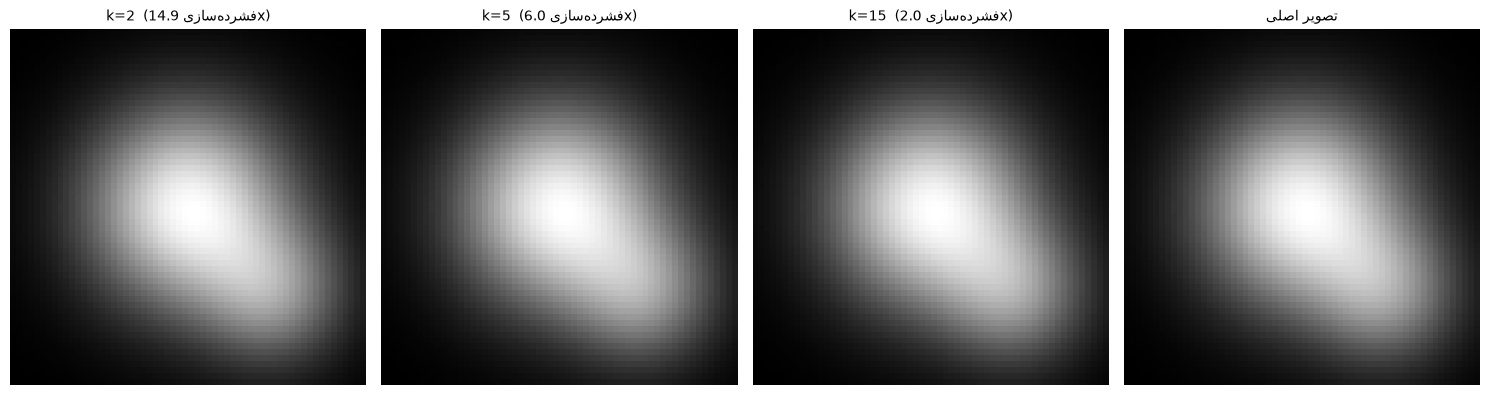

In [3]:
# یک تصویر ساختگی (یک الگوی ساده، شبیه یک تصویر واقعی با ساختار)
size = 60
xx, yy = np.meshgrid(np.linspace(-3, 3, size), np.linspace(-3, 3, size))
image = np.exp(-(xx**2 + yy**2) / 3) + 0.5 * np.exp(-((xx-1.5)**2 + (yy-1.5)**2) / 1.5)
image = torch.tensor(image, dtype=torch.float32)

U, S, Vt = torch.linalg.svd(image, full_matrices=False)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, k in zip(axes, [2, 5, 15, len(S)]):
    approx = low_rank_approx(U, S, Vt, k)
    compression_ratio = (image.numel()) / (k * (image.shape[0] + image.shape[1] + 1))
    ax.imshow(approx, cmap="gray")
    label = "تصویر اصلی" if k == len(S) else f"k={k}  (فشرده‌سازی {compression_ratio:.1f}x)"
    ax.set_title(label, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()


📌 می‌بینید با نگه‌داشتن فقط چند مقدار تکین اول (به‌جای همه‌ی آن‌ها)، تصویر تقریباً همان کیفیت را دارد ولی حجم ذخیره‌سازی‌اش خیلی کمتر است — چون به‌جای کل ماتریس، فقط چند ستون از $U$، چند مقدار از $\Sigma$ و چند سطر از $V^\top$ را ذخیره می‌کنیم.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>





## بخش ۲: شبه‌وارون مور-پنروز (Moore–Penrose Pseudoinverse)

📘 برای ماتریس‌های مربعی، معمولاً یک «وارون» ($A^{-1}$) وجود دارد که $A^{-1}A = I$. اما اگر ماتریس مربعی نباشد (مثلاً معادلات بیشتر از مجهولات داریم — که در یادگیری ماشین خیلی رایج است: هزاران نمونه‌ی داده، فقط چند پارامتر) وارون معمولی اصلاً تعریف نمی‌شود.

**شبه‌وارون مور-پنروز** ($A^+$) این مشکل را حل می‌کند و مستقیماً از روی SVD ساخته می‌شود:

$$
A^+ = V \Sigma^+ U^\top
$$

($\Sigma^+$: هر مقدار تکین ناصفر را وارون می‌کنیم، یعنی $1/\sigma_i$)

کاربرد اصلی‌اش: حل مسئله‌ی **کمترین مربعات (Least Squares)** — پیدا کردن بهترین خط/صفحه‌ای که از میان چند نقطه‌ی داده عبور می‌کند، وقتی هیچ خطی دقیقاً از همه‌ی نقاط عبور نمی‌کند (که تقریباً همیشه همین‌طور است). این دقیقاً پایه‌ی **رگرسیون خطی** است که در جلسه ۱۸ به‌طور کامل می‌بینیم.

In [4]:
# چند نقطه‌ی داده که هیچ خط مستقیمی دقیقا از همه‌شان رد نمی‌شود
x_points = torch.tensor([0.0, 1.0, 2.0, 3.0, 4.0])
y_points = torch.tensor([1.1, 2.9, 4.8, 7.2, 8.9])

# می‌خواهیم بهترین خط y = m*x + b را پیدا کنیم
# این را به شکل ماتریسی می‌نویسیم: A @ [m, b] ≈ y
A = torch.stack([x_points, torch.ones_like(x_points)], dim=1)

A_pinv = torch.linalg.pinv(A)   # شبه‌وارون مور-پنروز
U1, S1,Vt1=torch.svd(A_pinv)
print(U1, S1,Vt1, sep='\n')
params = A_pinv @ y_points
m, b = params.tolist()



tensor([[ 0.3310,  0.9436],
        [-0.9436,  0.3310]])
tensor([0.8186, 0.1728])
tensor([[-0.7725,  0.0572],
        [-0.5015,  0.2202],
        [-0.2305,  0.3832],
        [ 0.0404,  0.5462],
        [ 0.3114,  0.7092]])


بهترین خط: y = 1.99 x + 1.00


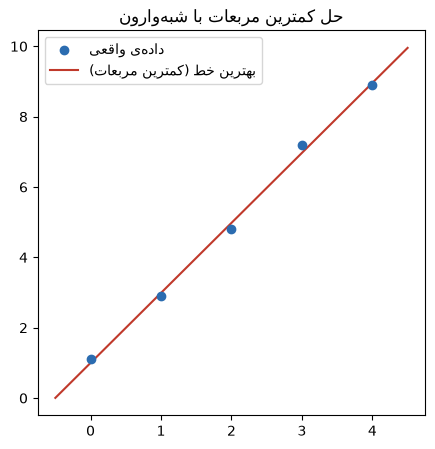

In [7]:
print(f"بهترین خط: y = {m:.2f} x + {b:.2f}")

plt.figure(figsize=(5, 5))
plt.scatter(x_points, y_points, color="#2b6cb0", label="داده‌ی واقعی", zorder=3)
xs = torch.linspace(-0.5, 4.5, 50)
plt.plot(xs, m*xs + b, color="#c0392b", label="بهترین خط (کمترین مربعات)")
plt.legend(); plt.title("حل کمترین مربعات با شبه‌وارون")
plt.show()

## بخش ۳: کارگاه عملی — روی داده‌ی پروژه‌ی خودتان

اگر پروژه‌ی شما شامل جدول امتیاز/تعامل کاربر-آیتم است (مثلاً کاربر-محصول، کاربر-مقاله)، همین حالا یک نسخه‌ی کوچک از آن را با چند خانه‌ی خالی بسازید و با `low_rank_approx` پیش‌بینی بگیرید. اگر پروژه‌ی شما این شکلی نیست، یک رابطه‌ی خطی ساده بین دو ویژگی‌ عددی از داده‌تان پیدا کنید (مثل قیمت و تقاضا) و با شبه‌وارون بهترین خط را پیدا کنید.

In [6]:
# فضای کار تیم شما 👇
# TODO


In [6]:
import numpy as np
import pandas as pd

df = pd.read_excel("Dataset.xlsx", sheet_name="design_matrix")
sub = df[df["scenario_id"] == 1].head(10)

x = sub["own_price"].to_numpy(dtype=float)
y = sub["own_price_rank"].to_numpy(dtype=float)   # varies: [2,5,3,2,1,5,4,4,5,3]

A = np.column_stack([x, np.ones_like(x)])
coef = np.linalg.pinv(A) @ y
a, b = coef

y_hat = A @ coef
ss_res = ((y - y_hat) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot

print(f"Best-fit line:  rank ≈ {a:.4f} · price + {b:.4f}")
print(f"R² = {r2:.4f},  RMSE = {np.sqrt(ss_res/len(y)):.4f}")

Best-fit line:  rank ≈ 0.3123 · price + 0.8983
R² = 0.7660,  RMSE = 0.6562


## جمع‌بندی و تکلیف


**تکلیف قبل از جلسه‌ی بعد:**
1. تمرین کارگاهی را کامل کنید.
2. فصل PCA از *Mathematics for Machine Learning* (فصل ۱۰) را مرور کنید.

**منابع این جلسه:**
- Deisenroth et al. — *Mathematics for Machine Learning*, فصل ۴ (کاربردهای SVD)
- Strang — *Linear Algebra and Learning from Data*, فصل ۱ و ۲ (Low-Rank Approximation, Least Squares)
